This notebook accompanies [03-learning-from-data](https://xing-phys.github.io/ai-for-physics/03-learning-from-data.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Learning from measurements and configurations 

## A familiar experiment is already a learning problem

Measuring a spring constant or fitting a decay rate involves the central ideas of machine learning: choose a representation, infer its parameters from data, and assess predictions on information not used to choose it. Neural networks extend the representation; they do not replace this logic. We begin with models simple enough to solve exactly.

The prerequisites are the probability and matrix tools of Chapter 2. The goals are to derive least squares from a measurement model, understand regularization as a physical and statistical choice, derive probabilistic classification, and discover collective coordinates through principal components. These tools will reappear in quantum-state optimization, inverse problems, and experimental design.

## Linear regression from a likelihood

Let each measured scalar $y_i$ satisfy

$$
y_i=\sum_{a=1}^P\theta_a\phi_a(x_i)+\epsilon_i,
\qquad \epsilon_i\sim\mathcal N(0,\sigma_i^2),
$$

with independent errors. The features $\phi_a$ are chosen functions: $1,x,x^2$ for a polynomial, or physically motivated terms such as $x$ and $x^3$ for an anharmonic force. The model is linear in its adjustable coefficients even if the features depend nonlinearly on $x$.

Write $X_{ia}=\phi_a(x_i)$ and $W_{ij}=\delta_{ij}/\sigma_i^2$. Independence makes the likelihood a product of Gaussians. Taking its negative logarithm converts the product to a sum:

$$
-\log p(y\mid\theta)=\frac12(y-X\theta)^TW(y-X\theta)
+\frac12\sum_i\log(2\pi\sigma_i^2).
$$

When variances are known and independent of $\theta$, the second term is constant. Maximizing likelihood therefore minimizes weighted least squares. Differentiating the quadratic gives $-X^TW(y-X\theta)=0$, or the normal equations

$$
X^TWX\widehat\theta=X^TWy.
$$ 

If the matrix is invertible, this specifies a unique solution. In computation, QR factorization or singular-value methods are usually preferable to explicitly forming an inverse; squaring $X$ to make $X^TX$ also squares its condition number. For correlated Gaussian errors, replace diagonal $W$ by the full inverse covariance and include its normalization if that covariance is inferred.

### Worked calculation: an anharmonic force

Let $F(x)=-kx-\lambda x^3$. Taking features $(-x,-x^3)$ makes $\theta=(k,\lambda)$. If all measurements use $x=\pm a$, then $x^3=a^2x$, so the two columns of $X$ are proportional. The experiment determines only $k+\lambda a^2$. No optimizer can identify $k$ and $\lambda$ separately. Measurements at at least two distinct nonzero magnitudes remove this exact degeneracy, although small displacements may still make $\lambda$ imprecise.

For homoscedastic noise $\sigma^2$, substitution of $y=X\theta_*+\epsilon$ gives $\widehat\theta=\theta_*+(X^TX)^{-1}X^T\epsilon$. Hence the estimate is unbiased when the model is correct, and its covariance is

$$
\operatorname{Cov}(\widehat\theta)=\sigma^2(X^TX)^{-1}.
$$ 

At a new input with feature vector $\phi_*$, the variance of the predicted mean is $\sigma^2\phi_*^T(X^TX)^{-1}\phi_*$. A future noisy observation has an additional $\sigma^2$. Confusing these two uncertainty questions produces intervals that are too narrow for future measurements.

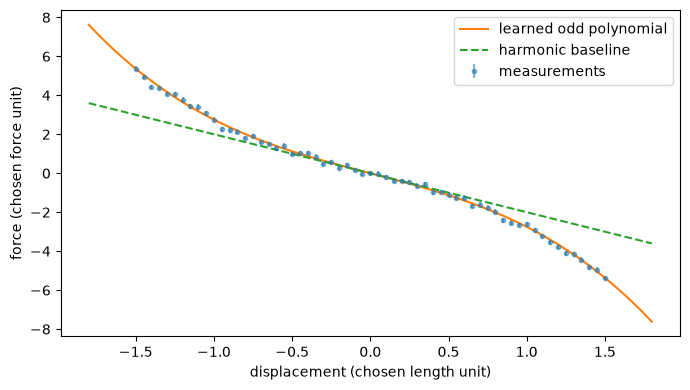

Estimated (k, lambda): [2.0902 0.6609]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(302)
x = np.linspace(-1.5, 1.5, 61)
sigma = 0.12
force = -2*x - 0.7*x**3 + rng.normal(0, sigma, x.size)
X = np.column_stack([-x, -x**3])
coef = np.linalg.lstsq(X, force, rcond=None)[0]
cov = sigma**2 * np.linalg.inv(X.T @ X)
assert np.all(np.abs(coef - [2.0, 0.7]) < 5*np.sqrt(np.diag(cov)))
grid = np.linspace(-1.8, 1.8, 200)
plt.figure(figsize=(7, 4))
plt.errorbar(x, force, yerr=sigma, fmt='.', alpha=.55, label='measurements')
plt.plot(grid, -coef[0]*grid-coef[1]*grid**3, label='learned odd polynomial')
plt.plot(grid, -2*grid, '--', label='harmonic baseline')
plt.xlabel('displacement (chosen length unit)')
plt.ylabel('force (chosen force unit)')
plt.legend(); plt.tight_layout(); plt.show()
print('Estimated (k, lambda):', np.round(coef, 4))

## Why fitting harder can predict worse

A degree-$N-1$ polynomial can interpolate $N$ distinct scalar data points exactly. If the measurements contain noise, zero training error can encode fluctuations rather than the physical relation. **Generalization** means predictive performance on new inputs and measurements from a specified distribution. It is always relative to that distribution.

Let the true regression function be $f_*(x)=\mathbb E[y\mid x]$ and let $\widehat f_D$ be the result of fitting dataset $D$. At a fixed $x$, write $y=f_*(x)+\epsilon$ with zero-mean noise independent of the fitting data. Add and subtract $\mathbb E_D\widehat f_D(x)$ inside the squared error. Averaging removes cross terms and yields

$$
\mathbb E_{D,\epsilon}[(y-\widehat f_D(x))^2]
=\underbrace{\operatorname{Var}(\epsilon\mid x)}_{\text{measurement noise}}
+\underbrace{(f_*(x)-\mathbb E_D\widehat f_D(x))^2}_{\text{squared bias}}
+\underbrace{\operatorname{Var}_D(\widehat f_D(x))}_{\text{fitting variability}}.
$$ 

This identity assumes squared loss and the stated noise model; it does not say every increase of model size monotonically trades bias for variance. Modern overparameterized systems can have more complicated behavior. Its lasting lesson is that training error alone omits variability and irreducible noise.

Divide data into training, validation, and test sets. Training determines coefficients; validation chooses features, regularization, stopping time, or architecture; the final test assesses the resulting procedure. Repeatedly changing a model after looking at the test set turns it into another validation set. For trajectories, lattices, or repeated experimental shots, split by independent runs or physical systems when that matches the intended deployment. Adjacent time points can otherwise leak nearly duplicate information across the split.

## Regularization and prior information

Ridge regression minimizes

$$
L_\alpha(\theta)=\frac12\|y-X\theta\|^2
+\frac\alpha2\|\theta\|^2,
\qquad \alpha>0.
$$

Differentiation gives $(X^TX+\alpha I)\widehat\theta_\alpha=X^Ty$. Using $X=U\Sigma V^T$, the solution along $v_a$ is $s_a(u_a^Ty)/(s_a^2+\alpha)$. Unregularized inversion would divide by $s_a$; ridge suppresses weakly observed directions. It introduces bias deliberately to reduce sensitivity.

If the measurement variance is $\sigma^2$ and the prior is an independent Gaussian $\theta\sim\mathcal N(0,\tau^2I)$, the negative log posterior, multiplied by $\sigma^2$, has exactly this form with $\alpha=\sigma^2/\tau^2$. The posterior mode is ridge regression. This does not mean the prior is physically justified automatically. Coefficients with different units must be scaled or assigned distinct prior scales, and an intercept is often treated separately.

A penalty $\lambda\sum_a|\theta_a|$ encourages exact zeros and leads to sparse regression. Its derivative has a discontinuity at zero; Chapter 19 derives how thresholding can select candidate terms in physical equations. Regularization can also be structural: odd features enforce inversion symmetry, local features enforce limited interaction range, and conserved quantities can restrict possible dynamics.

## Classification is probability estimation

Suppose $y\in\{0,1\}$ labels two preparation conditions. A model produces $q_\theta(x)=p_\theta(y=1\mid x)$. For a scalar score $z=\theta^T\phi(x)$, the logistic function

$$
q=\frac{1}{1+e^{-z}}
$$

maps every real score to $(0,1)$. Equivalently, $\log[q/(1-q)]=z$, so the score is a log odds ratio. A Bernoulli likelihood gives the average cross-entropy

$$
L=-\frac1N\sum_i[y_i\log q_i+(1-y_i)\log(1-q_i)].
$$ 

Differentiate one term: $\partial L_i/\partial q_i=-y_i/q_i+(1-y_i)/(1-q_i)$ and $dq_i/dz_i=q_i(1-q_i)$, so $\partial L_i/\partial z_i=q_i-y_i$. Therefore $\nabla_\theta L=N^{-1}\sum_i(q_i-y_i)\phi(x_i)$. The cancellation is the practical reason this combination of output map and loss is convenient.

For $K$ classes, softmax gives $q_k=e^{z_k}/\sum_j e^{z_j}$, and the loss of a measured class $y$ is $-\log q_y$. Subtracting $\max_jz_j$ before exponentiation leaves probabilities unchanged and avoids overflow. Predicting the most probable class produces a decision, but loses uncertainty information. A model that assigns 0.51 and one that assigns 0.999 make the same decision and make very different claims.

### A classifier can learn a density ratio

Prepare equally many samples from distributions $p_0(x)$ and $p_1(x)$. Bayes' rule gives the optimal conditional classifier
$q_*(x)=p_1(x)/(p_0(x)+p_1(x))$. Thus

$$
\frac{q_*}{1-q_*}=\frac{p_1(x)}{p_0(x)}.
$$ 

If the class prior is unequal, a prior-odds factor appears. This connects classification with hypothesis testing and simulation-based inference. A finite trained classifier approximates this identity only to the extent that its probabilities are accurate under the relevant distributions. High accuracy alone does not certify a reliable likelihood ratio in rare tails.

## Principal components: discovering a coordinate

Let centered configurations be row vectors $x_i^T$ and $C=N^{-1}\sum_ix_ix_i^T$. We seek a unit vector $v$ maximizing the variance of projected data $z_i=v^Tx_i$. That variance is $v^TCv$. Introducing a multiplier for $v^Tv=1$ and differentiating gives $Cv=\lambda v$. The largest eigenvalue gives the maximum variance; subsequent orthogonal eigenvectors give the next directions. This is **principal-component analysis**, or PCA.

The same directions minimize mean squared reconstruction error. For a rank-$r$ orthogonal projection $P=\sum_{a=1}^rv_av_a^T$, the residual average is $\operatorname{tr}C-\sum_{a=1}^r\lambda_a$. Keeping the largest eigenvalues therefore loses the least variance among rank-$r$ linear projections. This is a geometric criterion; a low-variance feature can still be the most scientifically important one.

### Spins and an emerging order parameter

For spins $s_j=\pm1$ with a translation-invariant, spin-flip-symmetric distribution, $\langle s_j\rangle=0$ in a finite equilibrium ensemble and $C_{ij}=\langle s_is_j\rangle$. If long-range ferromagnetic correlations dominate, the uniform vector $v_j=1/\sqrt L$ has eigenvalue $\lambda_0=L^{-1}\sum_{ij}C_{ij}$. Its projection is $v^Ts=\sqrt L\,m$, where $m=L^{-1}\sum_js_j$ is magnetization. Thus PCA can recover a familiar collective variable from correlation structure. It need not do so for frustrated, topological, or strongly inhomogeneous systems.

In [2]:
import numpy as np
rng = np.random.default_rng(303)
N, L = 4000, 24
# A synthetic two-domain ensemble, not a thermal Ising simulation.
domain = rng.choice([-1.0, 1.0], size=(N, 1))
flips = np.where(rng.random((N, L)) < .08, -1.0, 1.0)
spins = domain * flips
centered = spins - spins.mean(axis=0)
values, vectors = np.linalg.eigh(centered.T @ centered / N)
leading = vectors[:, -1]
uniform = np.ones(L) / np.sqrt(L)
overlap = abs(leading @ uniform)
assert overlap > .99
print(f'Overlap of PCA direction with magnetization: {overlap:.5f}')

Overlap of PCA direction with magnetization: 0.99995


The example is intentionally synthetic. It checks the relationship between a common collective sign and the covariance eigenvector; it does not simulate a phase transition or estimate a critical temperature.

## Research bridge and limitations

Configuration-based phase recognition [@f-carrasquilla], PCA studies of ordering [@f-wang], and confusion-based phase-boundary proposals [@f-confusion] motivated broad work on learning physical representations. Their strengths differ: supervised models use labels, PCA uses second moments, and confusion studies how classification changes under trial boundaries. None substitutes for defining the thermodynamic question and controlling finite-size effects. A boundary that moves with detector preprocessing may describe the apparatus rather than the material.

A wider caution comes from experiments showing that large networks can fit random labels [@f-zhang]. Those observations establish that fitting capacity alone cannot explain generalization in the tested settings. They do not imply that physical structure or regularization is useless. Later chapters use symmetries and variational principles because these encode specific, testable restrictions.

## Exercises and selected solutions

1. Derive weighted least squares for correlated Gaussian errors with covariance $C$ independent of $\theta$.
2. In the anharmonic-force example, explain why measurements at $x=0$ cannot separate $k$ and $\lambda$.
3. For an optimal classifier trained with class prior $\pi=p(y=1)$, derive $p_1(x)/p_0(x)$ in terms of $q_*(x)$.
4. A covariance matrix has eigenvalues $9,3,1,1$. What fraction of variance does a rank-two PCA representation retain? Does that certify retention of a conserved quantity?

**Solutions.** (1) The log likelihood is $\tfrac12(y-X\theta)^TC^{-1}(y-X\theta)+\tfrac12\log\det(2\pi C)$. Differentiation gives $X^TC^{-1}X\widehat\theta=X^TC^{-1}y$. (2) Both features vanish at equilibrium, so these measurements constrain neither coefficient; they can help infer an additional force offset if it is included. (3) Posterior odds equal likelihood ratio times prior odds: $p_1/p_0=[q_*/(1-q_*)](1-\pi)/\pi$. (4) Retained variance is $(9+3)/14=6/7$. A conserved quantity may occupy a discarded low-variance direction; the variance criterion provides no such guarantee.